# 02 · Bias–variance, underfitting, overfitting and regularization
**Do not confuse train–validation error gaps with exact mathematical variance decomposition.** These experiments use repeated splits of only the development set.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0,str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.data import load_data, feature_frame
active=ROOT/'data'/'active_dataset.csv'
if not active.exists():
    raise FileNotFoundError('Run python -m src.train first, then restart the notebook kernel.')
df=load_data(active)
print('Rows, columns:',df.shape)


Rows, columns: (395, 33)


In [2]:
depth=pd.read_csv(ROOT/'results'/'bias_variance_depth.csv')
reg=pd.read_csv(ROOT/'results'/'tree_regularization.csv')
print('Depth experiment entries:',len(depth))
display(depth.head())

Depth experiment entries: 56


,scenario,repeat,depth,train_rmse,validation_rmse
0,early,0,1,4.207857,4.490982
1,early,0,2,3.903397,4.390329
2,early,0,3,3.708152,4.683805
3,early,0,5,3.335429,4.734598
4,early,0,8,2.494492,5.322869


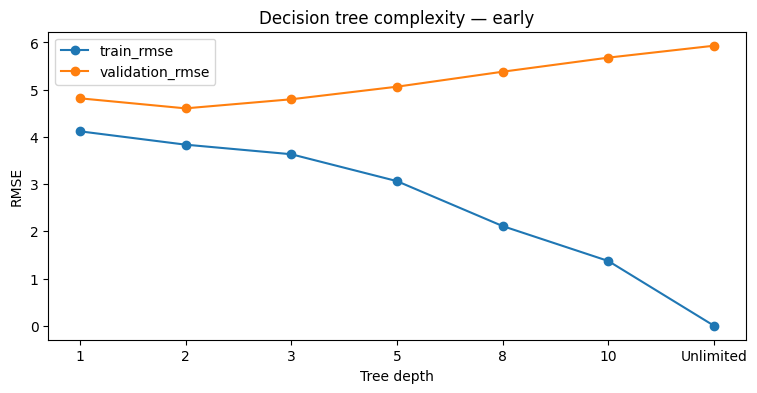

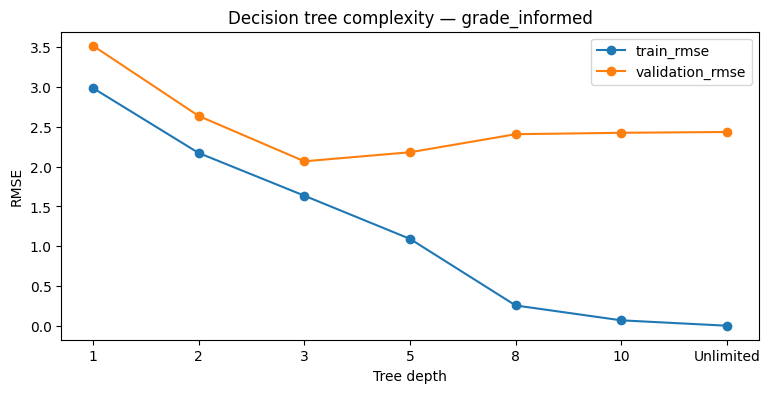

In [3]:
for scenario in ['early','grade_informed']:
    x=depth[depth.scenario==scenario].groupby('depth',sort=False)[['train_rmse','validation_rmse']].mean()
    ax=x.plot(marker='o',figsize=(9,4),title=f'Decision tree complexity — {scenario}')
    ax.set_ylabel('RMSE');ax.set_xlabel('Tree depth');plt.show()

**Interpretation:** A depth-1 tree can underfit (both errors high); an unrestricted tree may produce excellent training error but weaker validation error. Error trends, not model complexity alone, establish the observed behavior.

,train_rmse,validation_rmse
regularization,,
Unrestricted Baseline,0.000000,5.930224
Constrained Depth (depth=4),3.381142,4.901805
Min Leaf Size (leaf=8),3.118008,4.984628
Min Sample Split (split=12),2.413024,5.337093
Cost-Complexity Pruned (α=0.08),1.469177,5.488016
Cost-Complexity Pruned (α=0.25),2.496271,5.263946


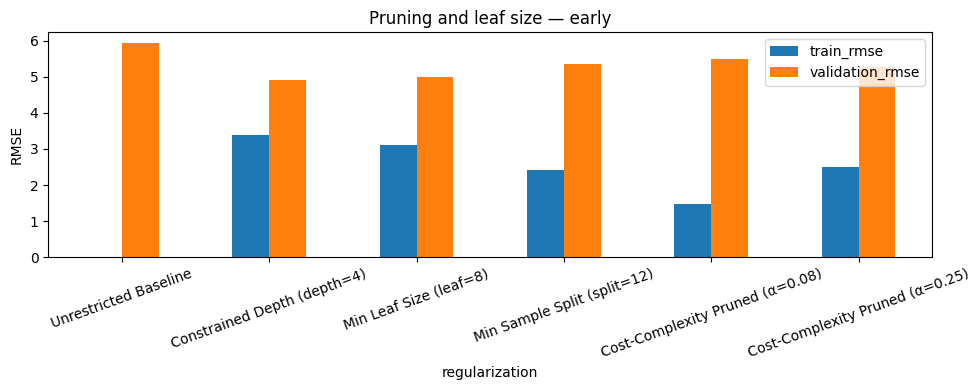

,train_rmse,validation_rmse
regularization,,
Unrestricted Baseline,0.000000,2.435863
Constrained Depth (depth=4),1.377964,2.194639
Min Leaf Size (leaf=8),1.391964,1.968316
Min Sample Split (split=12),1.039120,2.326069
Cost-Complexity Pruned (α=0.08),0.923663,2.359110
Cost-Complexity Pruned (α=0.25),1.345933,2.474278


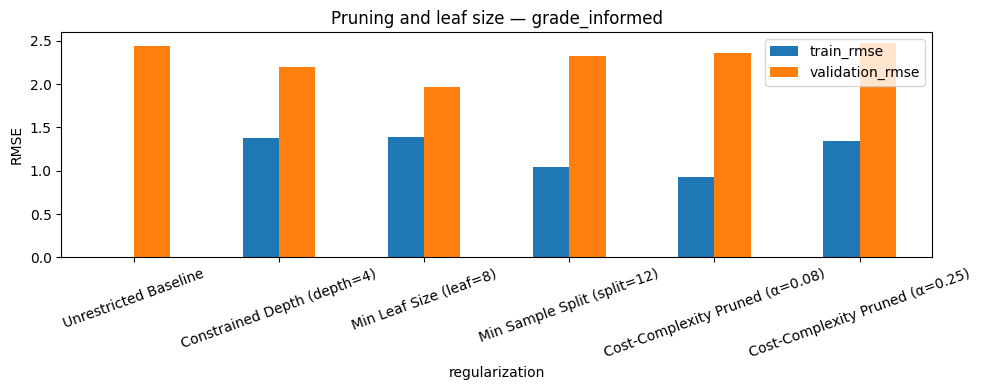

In [4]:
for scenario in ['early','grade_informed']:
    x=reg[reg.scenario==scenario].groupby('regularization',sort=False)[['train_rmse','validation_rmse']].mean()
    display(x)
    x.plot.bar(rot=20,figsize=(10,4),title=f'Pruning and leaf size — {scenario}')
    plt.ylabel('RMSE');plt.tight_layout();plt.show()

**Viva prompt:** Why does restricting tree depth *sometimes* improve validation performance and *sometimes* cause underfitting?